<a href="https://colab.research.google.com/github/Pronathan/na3a-programmering/blob/main/1016_fredag_brawlistic_disc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import random
from time import sleep

import pyfiglet

ascii_art = pyfiglet.figlet_format("Disc - listic - brawl !")

# STEG 2: Skapa en funktion för att visa loggan och ett välkomstmeddelande
def visa_startsida():
    print("=" * 91)
    print(ascii_art)
    print("=" * 91)
    # Exempel med typsnittet 'slant'
    banner_slant = pyfiglet.figlet_format("VÄLKOMMEN TILL DET ULTIMATA DISCGOLFSPELET!", font="slant")
    print(banner_slant)
    print("=" * 91)
    print()  # En tom rad för lite utrymme
    sleep(1.5) # Pausa lite så spelaren hinner se den snygga loggan

# STEG 3: Anropa funktionen längst upp i ditt program (innan spelet startar)
visa_startsida()

# Här fortsätter sedan resten av ditt vanliga program...
print("Laddar banan...")

hål = int(input("Vilket hål är du på? "))
längd = int(input("Hur långt är hålet?" ))
par = int(input("Vad har hålet för par? "))

print(f"hål {hål}")
print(f"{längd} meter")
print(f"par {par}")

stats= []

print("""
dd = distance driver
fd = fairway driver
md = midrange
tp = trowing putter
pp = putting putter
""")

def dd_kastlängd() -> int:
  return random.randint(60,120)

def fd_kastlängd() -> int:
  return random.randint(40,100)

def md_kastlängd() -> int:
  return random.randint(30,90)

def tp_kastlängd() -> int:
  return random.randint(15,50)

def pp_kastlängd() -> int:
  return random.randint(2,15)
sleep(1)

START_LÄNGD = längd

for i in range(10):
  antal_kast = 0
  längd = START_LÄNGD  # Återställ längden för varje ny runda!
  runda = {
      "kast": [],
      "par": par,
      "resultat": 0
  }

  #vilken disc man kastar och hur långt det är kvar
  while längd > 0:
    # 1. Välj disc och beräkna kastlängd baserat på nuvarande avstånd
    if längd > 100:
      kast = dd_kastlängd()
      längd -= kast
      if längd < 0:
        längd = 0
      antal_kast += 1
      runda["kast"].append(kast)
      print(f"Du kastade {kast} meter med en distance driver och det är nu {längd} meter kvar till korgen")
    elif längd <= 100 and längd > 70:
      kast = fd_kastlängd()
      längd -= kast
      if längd < 0:
        längd = 0
      antal_kast += 1
      runda["kast"].append(kast)
      print(f"Du kastade {kast} meter med en fairway driver och det är nu {längd} meter kvar till korgen")
    elif längd <= 70 and längd > 50:
      kast = md_kastlängd()
      längd -= kast
      if längd < 0:
        längd = 0
      antal_kast += 1
      runda["kast"].append(kast)
      print(f"Du kastade {kast} meter med en midrange och det är nu {längd} meter kvar till korgen")
    elif längd <= 50 and längd > 15:
      kast = tp_kastlängd()
      längd -= kast
      if längd < 0:
        längd = 0
      antal_kast += 1
      runda["kast"].append(kast)
      print(f"Du kastade {kast} meter med en throwing putter och det är nu {längd} meter kvar till korgen")
    else:
      kast = pp_kastlängd()
      längd -= kast
      if längd < 0:
        längd = 0
      antal_kast += 1
      runda["kast"].append(kast)
      print(f"Du kastade {kast} meter med en putting putter och det är nu {längd} meter kvar till korgen")

  runda["resultat"] = len(runda["kast"]) - par
  stats.append(runda)
  diff_till_par = antal_kast - par

  print("CHING! Yes, där gick discen i korgen")
  print(f"Det tog dig totalt {antal_kast} kast innan discen gick i korgen")

  if diff_till_par < 0:
    print(f"Du landade på {diff_till_par} under par")
  elif diff_till_par == 0:
    print(f"Snyggt. Du fick par")
  else:
    print(f"Du landade på {diff_till_par} över par")
  print(" ")
print(stats)

 ____  _                    _ _     _   _              
|  _ \(_)___  ___          | (_)___| |_(_) ___         
| | | | / __|/ __|  _____  | | / __| __| |/ __|  _____ 
| |_| | \__ \ (__  |_____| | | \__ \ |_| | (__  |_____|
|____/|_|___/\___|         |_|_|___/\__|_|\___|        
                                                       
 _                        _ _ 
| |__  _ __ __ ___      _| | |
| '_ \| '__/ _` \ \ /\ / / | |
| |_) | | | (_| |\ V  V /| |_|
|_.__/|_|  \__,_| \_/\_/ |_(_)
                              

 _    ___  _  __    __ ______  __  _____  __________   __   ____________    __ 
| |  / (_)(_)/ /   / //_/ __ \/  |/  /  |/  / ____/ | / /  /_  __/  _/ /   / / 
| | / / _ | / /   / ,< / / / / /|_/ / /|_/ / __/ /  |/ /    / /  / // /   / /  
| |/ / __ |/ /___/ /| / /_/ / /  / / /  / / /___/ /|  /    / / _/ // /___/ /___
|___/_/ |_/_____/_/ |_\____/_/  /_/_/  /_/_____/_/ |_/    /_/ /___/_____/_____/
                                                                             

KeyboardInterrupt: Interrupted by user

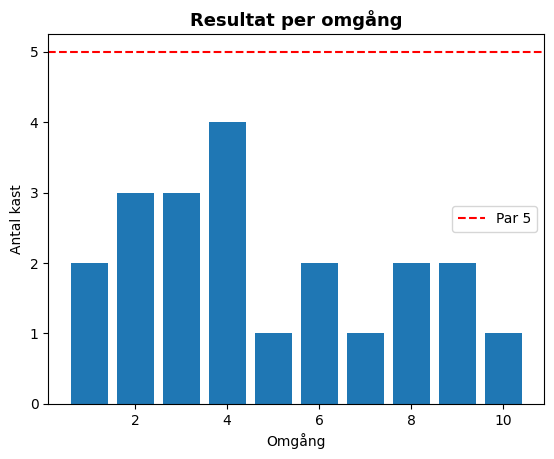

In [23]:
import matplotlib.pyplot as plt

# Hämta antalet kast för varje spelad runda i stats
kast = [len(runda["kast"]) for runda in stats]

# Skapa stapeldiagrammet
plt.bar(range(1, len(kast) + 1), kast)

# Lägg till en referenslinje för hålets Par
if 'par' in globals():
    plt.axhline(y=par, color='red', linestyle='--', label=f'Par {par}')

# Namnge axlarna och visa
plt.xlabel("Omgång") #Lägger till namn till x-axeln
plt.ylabel("Antal kast") #Lägger till namn till y-axeln
plt.title("Resultat per omgång", fontsize=13, fontweight='bold') # Skapar titel
plt.legend() #visar rutan med Par 5
plt.show() # visar diagram

In [47]:
import random
from time import sleep

import pyfiglet

ascii_art = pyfiglet.figlet_format("Disc-listic-brawl")

# STEG 2: Skapa en funktion för att visa loggan och ett välkomstmeddelande
def visa_startsida():
    print("=" * 91)
    print(ascii_art)
    print("=" * 91)
    # Exempel med typsnittet 'slant'
    banner_slant = pyfiglet.figlet_format("VÄLKOMMEN TILL DET ULTIMATA DISCGOLFSPELET!", font="slant")
    print(banner_slant)
    print("=" * 91)
    print()  # En tom rad för lite utrymme
    sleep(1.5) # Pausa lite så spelaren hinner se den snygga loggan

# STEG 3: Anropa funktionen längst upp i ditt program (innan spelet startar)
visa_startsida()

# Här fortsätter sedan resten av ditt vanliga program...
print("Laddar banan...")

hål = 1
längd = 238
par = 5

stats= []


print(f"hål {hål}")
print(f"{längd} meter")
print(f"par {par}")

print("""
dd = distance driver
fd = fairway driver
md = midrange
tp = trowing putter
pp = putting putter
""")

def dd_kastlängd() -> int:
  return random.randint(60,120)

def fd_kastlängd() -> int:
  return random.randint(40,100)

def md_kastlängd() -> int:
  return random.randint(30,90)

def tp_kastlängd() -> int:
  return random.randint(15,50)

def pp_kastlängd() -> int:
  return random.randint(2,15)
sleep(1)

START_LÄNGD = 238

for i in range(10):
  antal_kast = 0
  längd = START_LÄNGD  # Återställ längden för varje ny runda!
  runda = {
      "kast": [],
      "par": par,
      "resultat": 0
  }

  #vilken disc man kastar och hur långt det är kvar
  while längd > 0:
    # 1. Välj disc och beräkna kastlängd baserat på nuvarande avstånd
    if längd > 100:
      kast = dd_kastlängd()
      längd -= kast
      if längd < 0:
        längd = 0
      antal_kast += 1
      runda["kast"].append(kast)
      print(f"Du kastade {kast} meter med en distance driver och det är nu {längd} meter kvar till korgen")
    elif längd <= 100 and längd > 70:
      kast = fd_kastlängd()
      längd -= kast
      if längd < 0:
        längd = 0
      antal_kast += 1
      runda["kast"].append(kast)
      print(f"Du kastade {kast} meter med en fairway driver och det är nu {längd} meter kvar till korgen")
    elif längd <= 70 and längd > 50:
      kast = md_kastlängd()
      längd -= kast
      if längd < 0:
        längd = 0
      antal_kast += 1
      runda["kast"].append(kast)
      print(f"Du kastade {kast} meter med en midrange och det är nu {längd} meter kvar till korgen")
    elif längd <= 50 and längd > 15:
      kast = tp_kastlängd()
      längd -= kast
      if längd < 0:
        längd = 0
      antal_kast += 1
      runda["kast"].append(kast)
      print(f"Du kastade {kast} meter med en throwing putter och det är nu {längd} meter kvar till korgen")
    else:
      kast = pp_kastlängd()
      längd -= kast
      if längd < 0:
        längd = 0
      antal_kast += 1
      runda["kast"].append(kast)
      print(f"Du kastade {kast} meter med en putting putter och det är nu {längd} meter kvar till korgen")

  runda["resultat"] = len(runda["kast"]) - par
  stats.append(runda)
  diff_till_par = antal_kast - par

  print("CHING! Yes, där gick discen i korgen")
  print(f"Det tog dig totalt {antal_kast} kast innan discen gick i korgen")

  if diff_till_par < 0:
    print(f"Du landade på {diff_till_par} under par")
  elif diff_till_par == 0:
    print(f"Snyggt. Du fick par")
  else:
    print(f"Du landade på {diff_till_par} över par")
  print(" ")
print(stats)

 ____  _               _ _     _   _           _                        _ 
|  _ \(_)___  ___     | (_)___| |_(_) ___     | |__  _ __ __ ___      _| |
| | | | / __|/ __|____| | / __| __| |/ __|____| '_ \| '__/ _` \ \ /\ / / |
| |_| | \__ \ (_|_____| | \__ \ |_| | (_|_____| |_) | | | (_| |\ V  V /| |
|____/|_|___/\___|    |_|_|___/\__|_|\___|    |_.__/|_|  \__,_| \_/\_/ |_|
                                                                          

 _    ___  _  __    __ ______  __  _____  __________   __   ____________    __ 
| |  / (_)(_)/ /   / //_/ __ \/  |/  /  |/  / ____/ | / /  /_  __/  _/ /   / / 
| | / / _ | / /   / ,< / / / / /|_/ / /|_/ / __/ /  |/ /    / /  / // /   / /  
| |/ / __ |/ /___/ /| / /_/ / /  / / /  / / /___/ /|  /    / / _/ // /___/ /___
|___/_/ |_/_____/_/ |_\____/_/  /_/_/  /_/_____/_/ |_/    /_/ /___/_____/_____/
                                                                               
    ____  ____________   __  ____  ____________  ______  _________ 
 

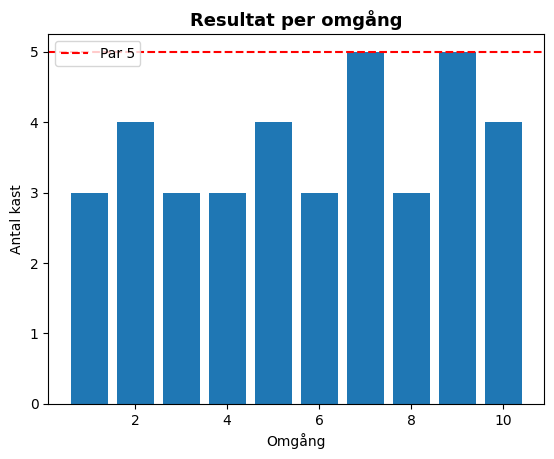

In [48]:
import matplotlib.pyplot as plt

# Hämta antalet kast för varje spelad runda i stats
kast = [len(runda["kast"]) for runda in stats]

# Skapa stapeldiagrammet
plt.bar(range(1, len(kast) + 1), kast)

# Lägg till en referenslinje för hålets Par
if 'par' in globals():
    plt.axhline(y=par, color='red', linestyle='--', label=f'Par {par}')

# Namnge axlarna och visa
plt.xlabel("Omgång") #Lägger till namn till x-axeln
plt.ylabel("Antal kast") #Lägger till namn till y-axeln
plt.title("Resultat per omgång", fontsize=13, fontweight='bold') # Skapar titel
plt.legend() #visar rutan med Par 5
plt.show() # visar diagram

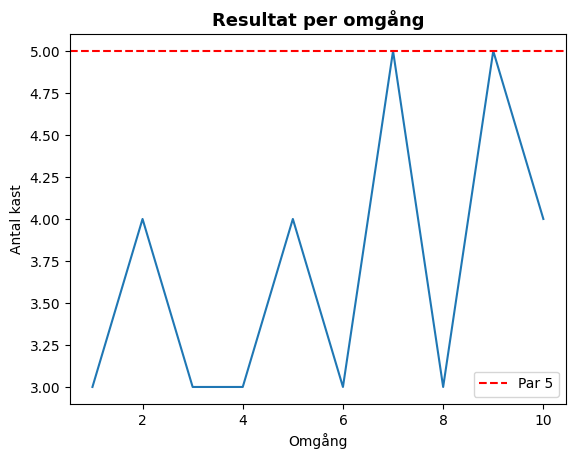

In [49]:
import matplotlib.pyplot as plt

# Hämta antalet kast för varje spelad runda i stats
kast = [len(runda["kast"]) for runda in stats]

# 2. Skapa linjediagrammet
plt.plot(range(1, len(kast) + 1), kast)

# Lägg till en referenslinje för hålets Par
if 'par' in globals():
    plt.axhline(y=par, color='red', linestyle='--', label=f'Par {par}')

# Namnge axlarna och visa
plt.xlabel("Omgång") #Lägger till namn till x-axeln
plt.ylabel("Antal kast") #Lägger till namn till y-axeln
plt.title("Resultat per omgång", fontsize=13, fontweight='bold') # Skapar titel
plt.legend() #visar rutan med Par 5
plt.show() # visar diagram